In [2]:
pip install ucimlrepo

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
from ucimlrepo import fetch_ucirepo

# fetch dataset
phiusiil_phishing_url_website = fetch_ucirepo(id=967)

# data (as pandas dataframes)
x = phiusiil_phishing_url_website.data.features
y = phiusiil_phishing_url_website.data.targets

# metadata
print(phiusiil_phishing_url_website.metadata)

# variable information
print(phiusiil_phishing_url_website.variables)
df = pd.DataFrame(x).copy()
df['label'] = y

print("DataFrame prêt ! Forme :", df.shape)


{'uci_id': 967, 'name': 'PhiUSIIL Phishing URL (Website)', 'repository_url': 'https://archive.ics.uci.edu/dataset/967/phiusiil+phishing+url+dataset', 'data_url': 'https://archive.ics.uci.edu/static/public/967/data.csv', 'abstract': 'PhiUSIIL Phishing URL Dataset is a substantial dataset comprising 134,850 legitimate and 100,945 phishing URLs. Most of the URLs we analyzed, while constructing the dataset, are the latest URLs. Features are extracted from the source code of the webpage and URL. Features such as CharContinuationRate, URLTitleMatchScore, URLCharProb, and TLDLegitimateProb are derived from existing features.', 'area': 'Computer Science', 'tasks': ['Classification'], 'characteristics': ['Tabular'], 'num_instances': 235795, 'num_features': 54, 'feature_types': ['Real', 'Categorical', 'Integer'], 'demographics': [], 'target_col': ['label'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2024, 'last_updated': 'Sun May 12 

In [4]:
y.value_counts(normalize=True)

label
1        0.571895
0        0.428105
Name: proportion, dtype: float64

In [5]:
print(x.shape) #we got 54 explicative variables
print(y.shape) #we got 1 target

(235795, 54)
(235795, 1)


In [6]:
print("Nombre de lignes :", x.shape[0])
print("Nombre de features :", x.shape[1])
print("les types : ",x.dtypes.value_counts()) #type
#valeurs manquantes we know we got none
print(" valeurs manquantes de x : ", x.isnull().sum().sum())
print("valeurs manquantes de y : ", y.isnull().sum().sum())
#doublons
print("x :", x.duplicated().sum())
print("\n DISTRIBUTION DE LA CIBLE :")
print(y["label"].value_counts())
print(y["label"].value_counts(normalize=True))
print("\n===== VALEURS UNIQUES =====")
for col in x.columns:
    print(f"{col:35} | type = {x[col].dtype} | uniques = {x[col].nunique()}")

Nombre de lignes : 235795
Nombre de features : 54
les types :  int64      40
float64    10
object      4
Name: count, dtype: int64
 valeurs manquantes de x :  0
valeurs manquantes de y :  0
x : 0

 DISTRIBUTION DE LA CIBLE :
label
1    134850
0    100945
Name: count, dtype: int64
label
1    0.571895
0    0.428105
Name: proportion, dtype: float64

===== VALEURS UNIQUES =====
URL                                 | type = object | uniques = 235370
URLLength                           | type = int64 | uniques = 482
Domain                              | type = object | uniques = 220086
DomainLength                        | type = int64 | uniques = 101
IsDomainIP                          | type = int64 | uniques = 2
TLD                                 | type = object | uniques = 695
URLSimilarityIndex                  | type = float64 | uniques = 36360
CharContinuationRate                | type = float64 | uniques = 898
TLDLegitimateProb                   | type = float64 | uniques = 465
URLCh

In [7]:
print(x.describe().T)

                               count          mean            std        min  \
URLLength                   235795.0     34.573095      41.314153  13.000000   
DomainLength                235795.0     21.470396       9.150793   4.000000   
IsDomainIP                  235795.0      0.002706       0.051946   0.000000   
URLSimilarityIndex          235795.0     78.430778      28.976055   0.155574   
CharContinuationRate        235795.0      0.845508       0.216632   0.000000   
TLDLegitimateProb           235795.0      0.260423       0.251628   0.000000   
URLCharProb                 235795.0      0.055747       0.010587   0.001083   
TLDLength                   235795.0      2.764456       0.599739   2.000000   
NoOfSubDomain               235795.0      1.164758       0.600969   0.000000   
HasObfuscation              235795.0      0.002057       0.045306   0.000000   
NoOfObfuscatedChar          235795.0      0.024861       1.876249   0.000000   
ObfuscationRatio            235795.0    

## 📝 Observations principales de `describe().T`

L'analyse statistique permet d'identifier plusieurs caractéristiques importantes
dans les données.

### 1. `URLLength`

- Moyenne : **34.57**
- Médiane : **27**
- 75% des valeurs : **34**
- Maximum : **6097**

La moyenne est supérieure à la médiane et la valeur maximale est très élevée.
Cela indique une **forte asymétrie à droite** (*right-skewed distribution*) avec
des valeurs extrêmes.

Ces valeurs élevées peuvent correspondre à des URLs particulièrement longues.
Il ne faut pas supprimer automatiquement ces observations car la longueur
d'une URL peut constituer un **signal important pour détecter le phishing**.

### 2. `DomainLength`

- Moyenne : **21.47**
- Médiane : **20**
- Maximum : **110**

La distribution est moins extrême que celle de `URLLength`, mais certaines URLs
possèdent des domaines beaucoup plus longs que la majorité des observations.

### 3. `URLSimilarityIndex`

La médiane et le troisième quartile sont tous les deux égaux à **100**.

Cela montre que beaucoup d'observations sont concentrées autour de la valeur
maximale. Cette variable présente donc une distribution particulière et devra
être examinée plus précisément.

### 4. `TLDLegitimateProb`
Cette variable représente une probabilité liée au caractère légitime du
TLD (*Top-Level Domain*).

D'après `describe()` :

- 25% des valeurs sont inférieures ou égales à `0.006`
- 50% des valeurs sont inférieures ou égales à `0.080`
- 75% des valeurs sont inférieures ou égales à `0.523`
- maximum = `0.523`

La moitié des observations possède donc une valeur inférieure ou égale à
`0.080`. Les valeurs sont ainsi fortement concentrées dans les faibles
valeurs.

Cependant, cette analyse ne permet pas encore de savoir si cette variable
permet de distinguer les URLs phishing des URLs légitimes. Nous comparerons
sa distribution selon la variable cible `label`.

### 5. Variables binaires

Plusieurs variables sont codées en **0/1**, par exemple :

- `IsDomainIP`
- `HasObfuscation`
- `IsHTTPS`
- `HasTitle`
- `HasFavicon`
- `Robots`
- `Bank`
- `Pay`
- `Crypto`
- `HasPasswordField`

Pour ces variables, la moyenne représente directement la **proportion de
valeurs égales à 1**.

Par exemple, `IsDomainIP` a une moyenne de **0.0027**, ce qui signifie qu'environ
**0.27 %** des URLs utilisent directement une adresse IP comme domaine.

Certaines variables binaires sont donc très rares, mais cela ne signifie pas
qu'elles sont inutiles : une caractéristique rare peut être particulièrement
discriminante pour détecter une URL de phishing.

### 6. Variables de comptage avec forte asymétrie

Certaines variables présentent des valeurs maximales très élevées par rapport
à leur médiane :

- `LineOfCode` : médiane = **429**, maximum ≈ **442 666**
- `LargestLineLength` : médiane = **1 090**, maximum ≈ **13.98 millions**
- `NoOfImage` : médiane = **8**, maximum = **8 956**
- `NoOfCSS` : médiane = **2**, maximum = **35 820**
- `NoOfJS` : médiane = **6**, maximum = **6 957**
- `NoOfSelfRef` : médiane = **12**, maximum = **27 397**
- `NoOfExternalRef` : médiane = **10**, maximum = **27 516**

Ces variables sont fortement **asymétriques** et contiennent des valeurs
extrêmes.

Il faudra éventuellement étudier des transformations comme `log1p` lors de la
phase de préparation, mais aucune transformation ne sera appliquée
automatiquement à ce stade.

### 7. Différences d'échelle

Les variables numériques ont des échelles très différentes.

Par exemple :

- `URLCharProb` varie autour de **0 à 0.09**
- `URLLength` peut atteindre **6097**
- `LineOfCode` peut atteindre plusieurs centaines de milliers
- `LargestLineLength` peut atteindre plusieurs millions

Cette différence d'échelle devra être prise en compte pour certains modèles,
notamment **Logistic Regression** et **KNN**.

Le scaling sera réalisé plus tard dans le pipeline de prétraitement afin
d'éviter toute fuite de données (*data leakage*).

### Conclusion

L'analyse de `describe().T` montre principalement :

- des **distributions asymétriques** pour plusieurs variables ;
- des **valeurs extrêmes** dans certaines variables de comptage ;
- des **variables binaires parfois très rares** ;
- des **échelles très différentes** entre les features.

Ces observations seront prises en compte lors de la phase de préparation et
de modélisation.

In [8]:
data = x.copy()
data["label"] = y["label"]
comparison = data.groupby("label").mean(numeric_only=True).T
print(comparison)

label                                  0            1
URLLength                      45.720293    26.228610
DomainLength                   24.465144    19.228610
IsDomainIP                      0.006320     0.000000
URLSimilarityIndex             49.616973   100.000000
CharContinuationRate            0.728395     0.933176
TLDLegitimateProb               0.232099     0.281625
URLCharProb                     0.049999     0.060050
TLDLength                       2.819327     2.723382
NoOfSubDomain                   1.168894     1.161661
HasObfuscation                  0.004805     0.000000
NoOfObfuscatedChar              0.058071     0.000000
ObfuscationRatio                0.000323     0.000000
NoOfLettersInURL               28.106583    12.933059
LetterRatioInURL                0.568366     0.476705
NoOfDegitsInURL                 4.326217     0.050597
DegitRatioInURL                 0.064018     0.002115
NoOfEqualsInURL                 0.145386     0.000000
NoOfQMarkInURL              

### `URLLength`

La longueur moyenne des URLs est de **45.72** pour les URLs phishing
contre **26.23** pour les URLs légitimes.

Les URLs phishing sont donc en moyenne plus longues.
Cette variable semble potentiellement discriminante entre les deux classes.
### `DomainLength`

La longueur moyenne du domaine est de **24.47** pour les URLs phishing
contre **19.23** pour les URLs légitimes.

On observe une différence entre les deux classes, mais elle est moins
marquée que pour `URLLength`.

### `IsDomainIP`

`IsDomainIP` est une variable binaire :

- `1` → le domaine est une adresse IP ;
- `0` → le domaine n'est pas une adresse IP.

Il ne faut pas confondre cette variable avec la variable cible `label` :

- `label = 0` → URL phishing ;
- `label = 1` → URL légitime.

Pour les URLs phishing, la moyenne de `IsDomainIP` est de `0.006320` :

\[
0.006320 \times 100 = 0.632\%
\]

Cela signifie que **0.632 % des URLs phishing utilisent une adresse IP comme domaine**, tandis que **99.368 % n'utilisent pas d'adresse IP**.

Pour les URLs légitimes, la moyenne est de `0.000000`, ce qui signifie que **0 % utilisent une adresse IP comme domaine** et que **100 % n'en utilisent pas**.

On observe donc que l'utilisation d'une adresse IP comme domaine est très rare dans le dataset, mais qu'elle apparaît uniquement dans la classe phishing. Cette caractéristique peut donc être intéressante pour la classification.
### `HasObfuscation`

`HasObfuscation` est une variable binaire indiquant la présence d'une
obfuscation dans l'URL.

La moyenne de `HasObfuscation` est de **0.0048** pour les URLs phishing
contre **0** pour les URLs légitimes.

Comme cette variable est binaire (`0/1`), sa moyenne peut être interprétée
comme une proportion.

Pour les URLs phishing :

\[
0.0048 \times 100 = 0.48\%
\]

Cela signifie que **0.48 % des URLs phishing présentent une obfuscation**.

Pour les URLs légitimes, la moyenne est de **0**, ce qui signifie que
**0 % des URLs légitimes présentent une obfuscation**.

L'obfuscation est donc très rare dans l'ensemble du dataset, mais elle apparaît
uniquement dans la classe phishing. Cette caractéristique peut donc être
intéressante pour la classification.
### `URLSimilarityIndex`

La moyenne de `URLSimilarityIndex` est de **49.62** pour les URLs phishing
contre **100.00** pour les URLs légitimes.

On observe une différence très importante entre les deux classes. Les URLs
légitimes présentent en moyenne un indice de similarité beaucoup plus élevé
que les URLs phishing.

Cette variable semble donc potentiellement **très discriminante** pour la
classification.
### `CharContinuationRate`

`CharContinuationRate` est un ratio compris entre 0 et 1 qui représente le taux
de continuation des caractères dans l'URL.

La moyenne est de **0.7284** pour les URLs phishing contre **0.9332** pour les
URLs légitimes.

Comme cette variable est un ratio, ces valeurs correspondent respectivement
à environ **72.84 %** et **93.32 %**.

Les URLs légitimes présentent donc en moyenne un taux de continuation des
caractères plus élevé que les URLs phishing.

On observe une différence importante entre les deux classes. Cette variable
semble donc potentiellement discriminante pour la classification.
### `TLDLegitimateProb`

`TLDLegitimateProb` représente une probabilité associée à la légitimité du
TLD.

La moyenne est de **0.2321** pour les URLs phishing contre **0.2816** pour les
URLs légitimes.

Comme cette variable est une probabilité comprise entre 0 et 1, ces valeurs
correspondent respectivement à environ **23.21 %** et **28.16 %**.

On observe une différence entre les deux classes, mais elle reste relativement
faible par rapport à d'autres variables du dataset.

Cette variable pourrait donc apporter une information complémentaire, mais
elle semble moins discriminante à première vue.### `URLCharProb`

`URLCharProb` représente une probabilité associée aux caractères présents dans
l'URL.

La moyenne est de **0.04999** pour les URLs phishing contre **0.06005** pour les
URLs légitimes.

Comme cette variable est comprise entre 0 et 1, ces valeurs correspondent
respectivement à environ **4.999 %** et **6.005 %**.

On observe une légère différence entre les deux classes. Cette variable semble
donc moins discriminante à première vue, mais elle peut tout de même apporter
une information complémentaire au modèle.
### `TLDLength`

La moyenne de `TLDLength` est de **2.82** pour les URLs phishing contre
**2.72** pour les URLs légitimes.

La différence entre les deux classes est très faible. Cette variable semble
donc **peu discriminante** à première vue.
### `NoOfSubDomain`
`NoOfSubDomain` représente le nombre de sous-domaines présents dans l'URL.
La moyenne est de **1.17** pour les URLs phishing contre **1.16** pour les
URLs légitimes.
La différence est très faible. Cette variable semble donc peu discriminante
à première vue.

###`NoOfObfuscatedChar`
`NoOfObfuscatedChar` représente le nombre de caractères obfusqués présents
dans l'URL.
La moyenne est de **0.058** pour les URLs phishing contre **0** pour les URLs
légitimes.
Les URLs phishing contiennent donc en moyenne davantage de caractères
obfusqués.
La différence reste faible en valeur absolue, mais cette variable est
cohérente avec `HasObfuscation` et peut apporter une information
complémentaire.

###`ObfuscationRatio`

`ObfuscationRatio` représente la proportion de caractères obfusqués dans
l'URL.

La moyenne est de **0.000323** pour les URLs phishing contre **0** pour les
URLs légitimes.

Comme il s'agit d'un ratio, cela correspond à environ **0.0323 %** pour les
URLs phishing contre **0 %** pour les URLs légitimes.

L'obfuscation reste donc très rare dans le dataset, mais cette caractéristique
est davantage présente dans la classe phishing.
###`NoOfLettersInURL`

`NoOfLettersInURL` représente le nombre de lettres présentes dans l'URL.

La moyenne est de **28.11** pour les URLs phishing contre **12.93** pour les
URLs légitimes.

Les URLs phishing contiennent donc en moyenne **beaucoup plus de lettres**.

La différence entre les deux classes est importante. Cette variable semble
donc **potentiellement fortement** discriminante.
### `LetterRatioInURL`

`LetterRatioInURL` représente la **proportion de lettres présentes dans l'URL**.

La moyenne est de **0.568** pour les URLs phishing contre **0.477** pour les URLs légitimes.

Cela correspond respectivement à environ **56.8 %** et **47.7 %**.

On observe une différence entre les deux classes, mais elle est moins marquée que celle observée pour `NoOfLettersInURL`.
### `NoOfDegitsInURL`

`NoOfDegitsInURL` représente le **nombre de chiffres présents dans l'URL**.

La moyenne est de **4.33** pour les URLs phishing contre **0.05** pour les URLs légitimes.

Les URLs phishing contiennent donc en moyenne beaucoup plus de chiffres.

La différence est très importante entre les deux classes. Cette variable semble donc **très discriminante** à première vue.

### `DegitRatioInURL`

`DegitRatioInURL` représente la **proportion de chiffres présents dans l'URL**.

La moyenne est de **0.064** pour les URLs phishing contre **0.002** pour les URLs légitimes.

Cela correspond respectivement à environ **6.4 %** et **0.2 %**.

Les URLs phishing présentent donc une proportion de chiffres nettement plus élevée. Cette variable semble également **potentiellement très discriminante**.

### `NoOfEqualsInURL`

`NoOfEqualsInURL` représente le **nombre de caractères `=` présents dans l'URL**.

La moyenne est de **0.145** pour les URLs phishing contre **0** pour les URLs légitimes.

Les URLs phishing contiennent donc en moyenne davantage de caractères `=`.

La différence est notable, cette variable peut donc être **potentiellement discriminante** pour la classification.

### `NoOfQMarkInURL`

`NoOfQMarkInURL` représente le **nombre de caractères `?` présents dans l'URL**.

La moyenne est de **0.069** pour les URLs phishing contre **0** pour les URLs légitimes.

Les URLs phishing présentent donc davantage de caractères `?` en moyenne.

Cette différence peut rendre cette variable **potentiellement intéressante** pour la classification.

### `NoOfAmpersandInURL`

`NoOfAmpersandInURL` représente le **nombre de caractères `&` présents dans l'URL**.

La moyenne est de **0.059** pour les URLs phishing contre **0** pour les URLs légitimes.

Les URLs phishing contiennent donc en moyenne davantage de caractères `&`.

Cette différence peut apporter une information utile pour distinguer les deux classes.

### `NoOfOtherSpecialCharsInURL`

`NoOfOtherSpecialCharsInURL` représente le **nombre d'autres caractères spéciaux présents dans l'URL**.

La moyenne est de **3.80** pour les URLs phishing contre **1.24** pour les URLs légitimes.

Les URLs phishing contiennent donc en moyenne davantage de caractères spéciaux.

La différence entre les deux classes est importante. Cette variable semble donc **potentiellement discriminante**.

### `SpacialCharRatioInURL`

`SpacialCharRatioInURL` représente la **proportion de caractères spéciaux présents dans l'URL**.

La moyenne est de **0.083** pour les URLs phishing contre **0.048** pour les URLs légitimes.

Cela correspond respectivement à environ **8.3 %** et **4.8 %**.

Les URLs phishing présentent donc une proportion de caractères spéciaux plus élevée.

Cette différence peut rendre cette variable **potentiellement discriminante**.

### `IsHTTPS`

`IsHTTPS` est une variable binaire indiquant si l'URL utilise le protocole HTTPS.

La moyenne est de **0.492** pour les URLs phishing contre **1.000** pour les URLs légitimes.

Comme cette variable est binaire, cela correspond à environ **49.2 %** des URLs phishing utilisant HTTPS contre **100 %** des URLs légitimes.

On observe une différence très importante entre les deux classes. Cette variable semble donc **très discriminante** dans ce dataset.

Cependant, l'utilisation de HTTPS ne garantit pas à elle seule qu'un site est légitime. Il s'agit ici d'une observation propre à ce dataset.

### `LineOfCode`

`LineOfCode` représente le **nombre de lignes de code présentes dans la page web**.

La moyenne est de **65.73** pour les URLs phishing contre **1947.49** pour les URLs légitimes.

Les pages associées aux URLs légitimes contiennent donc en moyenne beaucoup plus de lignes de code.

La différence entre les deux classes est très importante. Cette variable semble donc **potentiellement très discriminante**.

### `LargestLineLength`

`LargestLineLength` représente la **longueur de la plus grande ligne de code de la page**.

La moyenne est de **20021.45** pour les URLs phishing contre **7375.92** pour les URLs légitimes.

Contrairement à `LineOfCode`, les pages phishing présentent ici une longueur maximale de ligne plus élevée en moyenne.

La différence entre les deux classes est importante. Cette variable semble donc **potentiellement discriminante**.
### `HasTitle`

`HasTitle` est une variable binaire indiquant si la page web possède un titre HTML.

La moyenne est de **0.678** pour les URLs phishing contre **0.999** pour les URLs légitimes.

Comme cette variable est binaire, cela correspond à environ **67.8 %** des pages phishing ayant un titre contre **99.9 %** des pages légitimes.

La différence entre les deux classes est importante. Cette variable semble donc **potentiellement discriminante** pour la classification.

### `Title`

`Title` représente le **titre de la page web**.

Il s'agit d'une variable textuelle avec un très grand nombre de valeurs différentes (**197 874 valeurs uniques**).

Il n'est donc pas pertinent de comparer directement les moyennes de cette variable.

Cette variable pourrait contenir des informations utiles, mais son traitement nécessite une approche spécifique pour les données textuelles. Une transformation ou une extraction de caractéristiques pourrait être envisagée, plutôt que de l'utiliser directement comme une variable catégorielle classique.

### `DomainTitleMatchScore`

`DomainTitleMatchScore` représente le **degré de correspondance entre le domaine et le titre de la page**.

La moyenne est de **16.55** pour les URLs phishing contre **75.27** pour les URLs légitimes.

Les pages légitimes présentent donc en moyenne une correspondance beaucoup plus élevée entre leur domaine et leur titre.

La différence entre les deux classes est très importante. Cette variable semble donc **potentiellement très discriminante**.

### `URLTitleMatchScore`

`URLTitleMatchScore` représente le **degré de correspondance entre l'URL et le titre de la page**.

La moyenne est de **21.20** pour les URLs phishing contre **75.27** pour les URLs légitimes.

Les URLs légitimes présentent donc en moyenne une correspondance beaucoup plus importante entre l'URL et le titre de la page.

La différence entre les deux classes est importante. Cette variable semble donc **potentiellement très discriminante**.

### `HasFavicon`

`HasFavicon` est une variable binaire indiquant si la page possède une **icône de site (favicon)**.

La moyenne est de **0.088** pour les URLs phishing contre **0.567** pour les URLs légitimes.

Comme cette variable est binaire, cela correspond à environ **8.8 %** des pages phishing possédant un favicon contre **56.7 %** des pages légitimes.

On observe une différence importante entre les deux classes. Cette variable semble donc **potentiellement discriminante**.

### `Robots`

`Robots` est une variable binaire indiquant la présence d'un élément lié au fichier ou mécanisme **robots.txt** du site.

La moyenne est de **0.066** pour les URLs phishing contre **0.417** pour les URLs légitimes.

Cela correspond à environ **6.6 %** des URLs phishing contre **41.7 %** des URLs légitimes.

La présence de cette caractéristique est donc beaucoup plus fréquente dans la classe légitime. Cette variable semble **potentiellement discriminante**.

### `IsResponsive`

`IsResponsive` est une variable binaire indiquant si la page web est **responsive**, c'est-à-dire adaptée aux différentes tailles d'écran.

La moyenne est de **0.317** pour les URLs phishing contre **0.854** pour les URLs légitimes.

Cela correspond à environ **31.7 %** des pages phishing contre **85.4 %** des pages légitimes.

La différence est importante entre les deux classes. Cette variable semble donc **potentiellement très discriminante**.

### `NoOfURLRedirect`

`NoOfURLRedirect` représente le **nombre de redirections d'URL**.

La moyenne est de **0.152** pour les URLs phishing contre **0.120** pour les URLs légitimes.

La différence entre les deux classes est relativement faible.

Cette variable semble donc **peu discriminante à première vue**, même si elle peut apporter une information complémentaire au modèle.

### `NoOfSelfRedirect`

`NoOfSelfRedirect` représente le **nombre de redirections vers la même URL ou le même site**.

La moyenne est de **0.057** pour les URLs phishing contre **0.027** pour les URLs légitimes.

Les URLs phishing présentent donc davantage de redirections internes en moyenne.

La différence reste relativement faible en valeur absolue. Cette variable semble donc **modérément discriminante à première vue**.
### `HasDescription`

`HasDescription` est une variable binaire indiquant si la page possède une **description**.

La moyenne est de **0.044** pour les URLs phishing contre **0.737** pour les URLs légitimes.

Comme cette variable est binaire, cela correspond à environ **4.4 %** des pages phishing ayant une description contre **73.7 %** des pages légitimes.

La différence entre les deux classes est très importante. Cette variable semble donc **potentiellement très discriminante**.

### `NoOfPopup`

`NoOfPopup` représente le **nombre de fenêtres pop-up présentes sur la page**.

La moyenne est de **0.010** pour les URLs phishing contre **0.380** pour les URLs légitimes.

Les pages légitimes présentent donc en moyenne davantage de pop-up dans ce dataset.

La différence est notable, mais les valeurs restent relativement faibles en moyenne. Cette variable peut donc être **potentiellement discriminante**.

### `NoOfiFrame`

`NoOfiFrame` représente le **nombre d'éléments iframe présents dans la page**.

La moyenne est de **0.085** pour les URLs phishing contre **2.715** pour les URLs légitimes.

Les pages légitimes contiennent donc en moyenne beaucoup plus d'iframes.

La différence entre les deux classes est importante. Cette variable semble donc **potentiellement très discriminante**.

### `HasExternalFormSubmit`

`HasExternalFormSubmit` est une variable binaire indiquant si la page contient un **formulaire dont l'envoi est dirigé vers une ressource externe**.

La moyenne est de **0.0043** pour les URLs phishing contre **0.0737** pour les URLs légitimes.

Comme cette variable est binaire, cela correspond à environ **0.43 %** des pages phishing contre **7.37 %** des pages légitimes.

La caractéristique reste relativement rare dans les deux classes, mais elle est davantage présente dans la classe légitime.

Cette variable peut donc apporter une information complémentaire au modèle.

### `HasSocialNet`

`HasSocialNet` est une variable binaire indiquant la présence d'éléments liés aux **réseaux sociaux** dans la page.

La moyenne est de **0.005** pour les URLs phishing contre **0.795** pour les URLs légitimes.

Cela correspond à environ **0.5 %** des pages phishing contre **79.5 %** des pages légitimes.

La différence est extrêmement importante. Cette variable semble donc **très discriminante** dans ce dataset.

### `HasSubmitButton`

`HasSubmitButton` est une variable binaire indiquant si la page contient un **bouton de soumission de formulaire**.

La moyenne est de **0.085** pour les URLs phishing contre **0.661** pour les URLs légitimes.

Cela correspond à environ **8.5 %** des pages phishing contre **66.1 %** des pages légitimes.

La différence entre les deux classes est importante. Cette variable semble donc **potentiellement très discriminante**.

### `HasHiddenFields`

`HasHiddenFields` est une variable binaire indiquant la présence de **champs cachés dans les formulaires de la page**.

La moyenne est de **0.093** pour les URLs phishing contre **0.591** pour les URLs légitimes.

Cela correspond à environ **9.3 %** des pages phishing contre **59.1 %** des pages légitimes.

La différence est importante entre les deux classes. Cette variable semble donc **potentiellement très discriminante**.

### `HasPasswordField`

`HasPasswordField` est une variable binaire indiquant si la page contient un **champ de mot de passe**.

La moyenne est de **0.054** pour les URLs phishing contre **0.138** pour les URLs légitimes.

Cela correspond à environ **5.4 %** des pages phishing contre **13.8 %** des pages légitimes.

On observe une différence entre les deux classes, mais elle est moins importante que pour plusieurs variables précédentes.

Cette variable semble donc **modérément discriminante à première vue**.

### `Bank`

`Bank` est une variable binaire indiquant la présence d'un élément associé au **domaine bancaire** dans les caractéristiques de la page.

La moyenne est de **0.054** pour les URLs phishing contre **0.182** pour les URLs légitimes.

Cela correspond à environ **5.4 %** des URLs phishing contre **18.2 %** des URLs légitimes.

La caractéristique est donc davantage présente dans la classe légitime.

La différence est intéressante, mais elle reste moins importante que celle observée pour certaines autres variables.

### `Pay`

`Pay` est une variable binaire indiquant la présence d'un élément associé au **paiement**.

La moyenne est de **0.060** pour les URLs phishing contre **0.369** pour les URLs légitimes.

Cela correspond à environ **6.0 %** des URLs phishing contre **36.9 %** des URLs légitimes.

La différence entre les deux classes est assez importante. Cette variable semble donc **potentiellement discriminante**.

### `Crypto`

`Crypto` est une variable binaire indiquant la présence d'un élément associé aux **cryptomonnaies**.

La moyenne est de **0.006** pour les URLs phishing contre **0.037** pour les URLs légitimes.

Cela correspond à environ **0.6 %** des URLs phishing contre **3.7 %** des URLs légitimes.

La caractéristique reste rare dans les deux classes. La différence existe, mais elle est relativement faible en valeur absolue.

Cette variable semble donc **peu discriminante à première vue**.

### `HasCopyrightInfo`

`HasCopyrightInfo` est une variable binaire indiquant la présence d'informations relatives au **copyright** sur la page.

La moyenne est de **0.057** pour les URLs phishing contre **0.808** pour les URLs légitimes.

Cela correspond à environ **5.7 %** des pages phishing contre **80.8 %** des pages légitimes.

La différence entre les deux classes est très importante. Cette variable semble donc **très discriminante** dans ce dataset.

### `NoOfImage`

`NoOfImage` représente le **nombre d'images présentes dans la page**.

La moyenne est de **0.866** pour les URLs phishing contre **44.947** pour les URLs légitimes.

Les pages légitimes contiennent donc en moyenne beaucoup plus d'images.

La différence entre les deux classes est extrêmement importante. Cette variable semble donc **potentiellement très discriminante**.

### `NoOfCSS`

`NoOfCSS` représente le **nombre de ressources CSS utilisées par la page**.

La moyenne est de **0.440** pour les URLs phishing contre **10.745** pour les URLs légitimes.

Les pages légitimes utilisent donc en moyenne beaucoup plus de ressources CSS.

La différence est importante entre les deux classes. Cette variable semble donc **potentiellement très discriminante**.

### `NoOfJS`

`NoOfJS` représente le **nombre de ressources JavaScript utilisées par la page**.

La moyenne est de **0.890** pour les URLs phishing contre **17.733** pour les URLs légitimes.

Les pages légitimes utilisent donc en moyenne beaucoup plus de ressources JavaScript.

La différence entre les deux classes est très importante. Cette variable semble donc **potentiellement très discriminante**.

### `NoOfSelfRef`

`NoOfSelfRef` représente le **nombre de références internes vers le même site ou domaine**.

La moyenne est de **0.496** pour les URLs phishing contre **113.410** pour les URLs légitimes.

Les pages légitimes présentent donc en moyenne beaucoup plus de références internes.

La différence entre les deux classes est extrêmement importante. Cette variable semble donc **potentiellement très discriminante**.

### `NoOfEmptyRef`

`NoOfEmptyRef` représente le **nombre de références ou liens vides présents dans la page**.

La moyenne est de **0.150** pour les URLs phishing contre **4.045** pour les URLs légitimes.

Les pages légitimes présentent donc en moyenne davantage de références vides.

La différence entre les deux classes est importante. Cette variable semble donc **potentiellement discriminante**.

### `NoOfExternalRef`

`NoOfExternalRef` représente le **nombre de références externes présentes dans la page**.

La moyenne est de **1.128** pour les URLs phishing contre **85.294** pour les URLs légitimes.

Les pages légitimes présentent donc en moyenne beaucoup plus de références externes.

La différence entre les deux classes est extrêmement importante. Cette variable semble donc **potentiellement très discriminante**.

In [9]:
import pandas as pd
pd.crosstab(x["TLD"], y["label"], normalize="columns") * 100

label,0,1
TLD,,
100,0.000991,0.000000
101,0.001981,0.000000
103,0.023775,0.000000
106,0.004953,0.000000
107,0.000991,0.000000
...,...,...
yt,0.001981,0.000000
za,0.129774,0.279570
zm,0.003963,0.006674


In [10]:
tld_distribution = pd.crosstab(
    x["TLD"],
    y["label"],
    normalize="columns"
) * 100

tld_distribution.columns = ["Phishing", "Legitimate"]

print("Top TLD - Phishing")
print(tld_distribution["Phishing"].sort_values(ascending=False).head(10))

print("\nTop TLD - Legitimate")
print(tld_distribution["Legitimate"].sort_values(ascending=False).head(10))

Top TLD - Phishing
TLD
com     43.359255
app      6.308386
co       4.917529
io       3.733716
net      3.069989
ru       2.955075
top      2.305216
dev      2.290356
org      2.247759
site     1.463173
Name: Phishing, dtype: float64

Top TLD - Legitimate
TLD
com    51.008528
org    12.253615
uk      4.503522
net     2.964776
de      2.454579
au      1.932518
jp      1.543938
edu     1.376344
it      1.237671
nl      1.139043
Name: Legitimate, dtype: float64


In [11]:
print("===== VARIABLES OBJECT =====")

for col in x.select_dtypes(include="object").columns:
    print(f"{col:15} | uniques = {x[col].nunique()}")
    print(x[col].head(5).tolist())
    print()

===== VARIABLES OBJECT =====
URL             | uniques = 235370
['https://www.southbankmosaics.com', 'https://www.uni-mainz.de', 'https://www.voicefmradio.co.uk', 'https://www.sfnmjournal.com', 'https://www.rewildingargentina.org']

Domain          | uniques = 220086
['www.southbankmosaics.com', 'www.uni-mainz.de', 'www.voicefmradio.co.uk', 'www.sfnmjournal.com', 'www.rewildingargentina.org']

TLD             | uniques = 695
['com', 'de', 'uk', 'com', 'org']

Title           | uniques = 197874
['à¸‚à¹ˆà¸²à¸§à¸ªà¸” à¸‚à¹ˆà¸²à¸§à¸§à¸±à¸™à¸™à¸µà¹‰ à¸‚à¹ˆà¸²à¸§à¸\x81à¸µà¸¬à¸² à¸‚à¹ˆà¸²à¸§à¸šà¸±à¸™à¹€à¸—à¸´à¸‡ à¸\xadà¸±à¸žà¹€à¸”à¸—à¸ªà¸”à¹ƒà¸«à¸¡à¹ˆà¸—à¸¸à¸\x81à¸§à¸±à¸™ &#8211; à¸‚à¹ˆà¸²à¸§à¸ªà¸” à¸‚à¹ˆà¸²à¸§à¸\x81à¸µà¸¬à¸² à¸‚à¹ˆà¸²à¸§à¸šà¸±à¸™à¹€à¸—à¸´à¸‡ à¸‚à¹ˆà¸²à¸§à¸§à¸±à¸™à¸™à¸µà¹‰ à¸\xadà¸±à¸›à¹€à¸”à¸•à¸‚à¹ˆà¸²à¸§à¸ªà¸²à¸£à¸£à¸§à¸”à¹€à¸£à¹‡à¸§à¸—à¸±à¸™à¹ƒà¸ˆ à¸žà¸£à¹‰à¸\xadà¸¡à¸£à¸±à¸šà¸Šà¸¡à¸ªà¸²à¸£à¸°à¸™à¹ˆà¸²à¸£à¸¹à¹‰à¸•à¹ˆà¸²à¸‡à¹† à¹„à¸”à¹‰à¸Ÿà¸£à¸µà¸•à¸¥à¸\xadà¸” 24à¸Šà¸±à¹ˆà¸§

## Variables de type `object`

Le dataset contient 4 variables de type `object` : `URL`, `Domain`, `TLD` et `Title`.

- **`URL`** : contient l'URL complète. Elle possède **235 370 valeurs uniques**, donc il s'agit d'une variable à très haute cardinalité.
- **`Domain`** : contient le nom du domaine avec **220 086 valeurs uniques**. Cette variable est également à très haute cardinalité.
- **`TLD`** : contient l'extension du domaine (`com`, `org`, `uk`, etc.) avec **695 catégories différentes**. C'est une variable catégorielle qui pourra éventuellement être encodée.
- **`Title`** : contient le titre de la page web avec **197 874 valeurs uniques**. Il s'agit d'une variable textuelle à haute cardinalité.

Les variables `URL`, `Domain` et `Title` ne seront donc pas encodées directement avec un One-Hot Encoding, car elles contiennent un très grand nombre de valeurs différentes. Nous examinerons plutôt les variables numériques déjà extraites de ces informations.

Pour `TLD`, nous analyserons d'abord la fréquence des différentes catégories afin de déterminer la meilleure représentation pour le modèle.

In [12]:
tld_counts = x["TLD"].value_counts()

print("Nombre de TLD différents :", x["TLD"].nunique())

print("\n===== 30 TLD les plus fréquents =====")
print(tld_counts.head(30))

print("\n===== Statistiques des fréquences =====")
print(tld_counts.describe())

print("\n===== TLD rares =====")
print("TLD avec 1 seule occurrence :", (tld_counts == 1).sum())
print("TLD avec moins de 5 occurrences :", (tld_counts < 5).sum())
print("TLD avec moins de 10 occurrences :", (tld_counts < 10).sum())

Nombre de TLD différents : 695

===== 30 TLD les plus fréquents =====
TLD
com     112554
org      18793
net       7097
app       6508
uk        6395
co        5422
io        4201
de        3996
ru        3875
au        2979
dev       2345
top       2329
jp        2219
it        1887
edu       1861
fr        1858
br        1846
nl        1727
ca        1614
info      1566
site      1482
xyz       1473
link      1463
in        1379
pl        1339
gov       1276
cf        1203
ga        1111
us        1108
me        1006
Name: count, dtype: int64

===== Statistiques des fréquences =====
count       695.000000
mean        339.273381
std        4365.963344
min           1.000000
25%           2.000000
50%           6.000000
75%          29.000000
max      112554.000000
Name: count, dtype: float64

===== TLD rares =====
TLD avec 1 seule occurrence : 152
TLD avec moins de 5 occurrences : 315
TLD avec moins de 10 occurrences : 408


### `TLD`

`TLD` est une variable catégorielle qui représente l'extension du domaine,
comme `com`, `org`, `net`, `uk`, etc.

Le dataset contient **695 TLD différents**, mais leur fréquence est **très
déséquilibrée.**

Le TLD **`com`** est largement dominant avec **112 554 occurrences**,
suivi de `org` avec **18 793 occurrences** et `net` avec **7 097 occurrences**.

On observe également que de nombreux TLD sont très rares :

- **152 TLD** apparaissent une seule fois ;
- **315 TLD** apparaissent moins de 5 fois ;
- **408 TLD** apparaissent moins de 10 fois.

La médiane des fréquences est seulement de **6 occurrences**, alors que la
moyenne est de **339.27 occurrences**. Cette différence importante montre
que quelques TLD très fréquents, notamment `com`, augmentent fortement la
moyenne.

Pour l'analyse par classe, `com` est également le TLD le plus fréquent dans
les deux classes : **43.36 % des URLs phishing** et **51.01 % des URLs
légitimes** utilisent ce TLD. Cela montre que `com` est très fréquent dans
les deux classes et ne permet donc pas, à lui seul, de distinguer clairement
les URLs phishing des URLs légitimes.

La variable `TLD` peut néanmoins apporter une information complémentaire au
modèle grâce aux différences de répartition entre les catégories. Cependant,
en raison du nombre important de catégories rares, nous devrons réfléchir à
leur traitement avant l'encodage.

In [13]:
from sklearn.model_selection import train_test_split
x_train,x_test, y_train, y_test= train_test_split(x, y["label"], test_size=0.2,random_state=42,stratify=y["label"])
print("X_train :", x_train.shape)
print("X_test  :", x_test.shape)
print("y_train :", y_train.shape)
print("y_test  :", y_test.shape)
#conservation de distrubition et proportion de train et test
print("Train :")
print(y_train.value_counts(normalize=True))

print("\nTest :")
print(y_test.value_counts(normalize=True))

X_train : (188636, 54)
X_test  : (47159, 54)
y_train : (188636,)
y_test  : (47159,)
Train :
label
1    0.571895
0    0.428105
Name: proportion, dtype: float64

Test :
label
1    0.571895
0    0.428105
Name: proportion, dtype: float64


Pourquoi faisons-nous cette séparation maintenant ?
Parce qu'on veut éviter **la data leakage.**

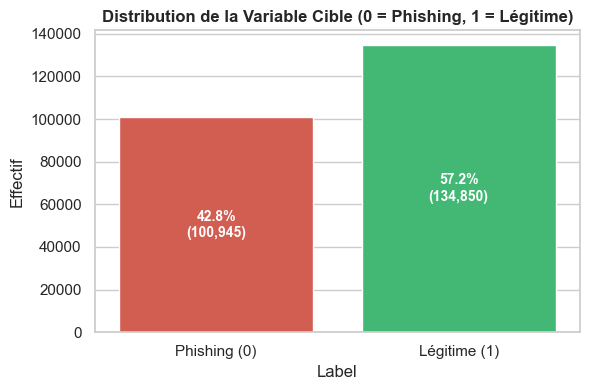

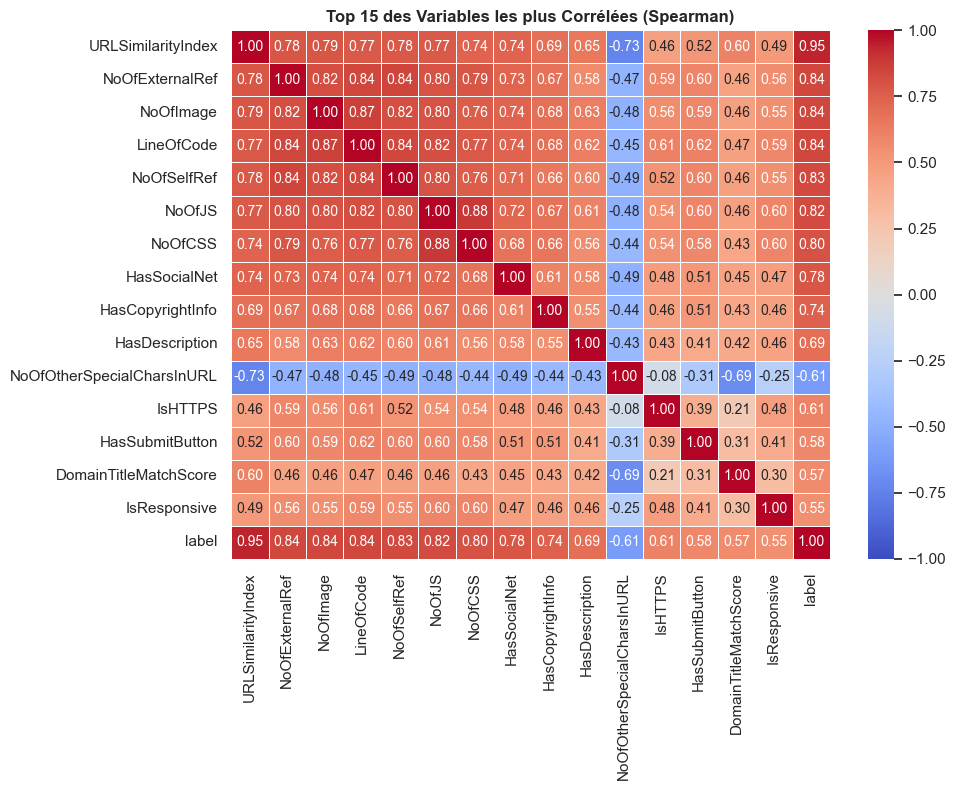

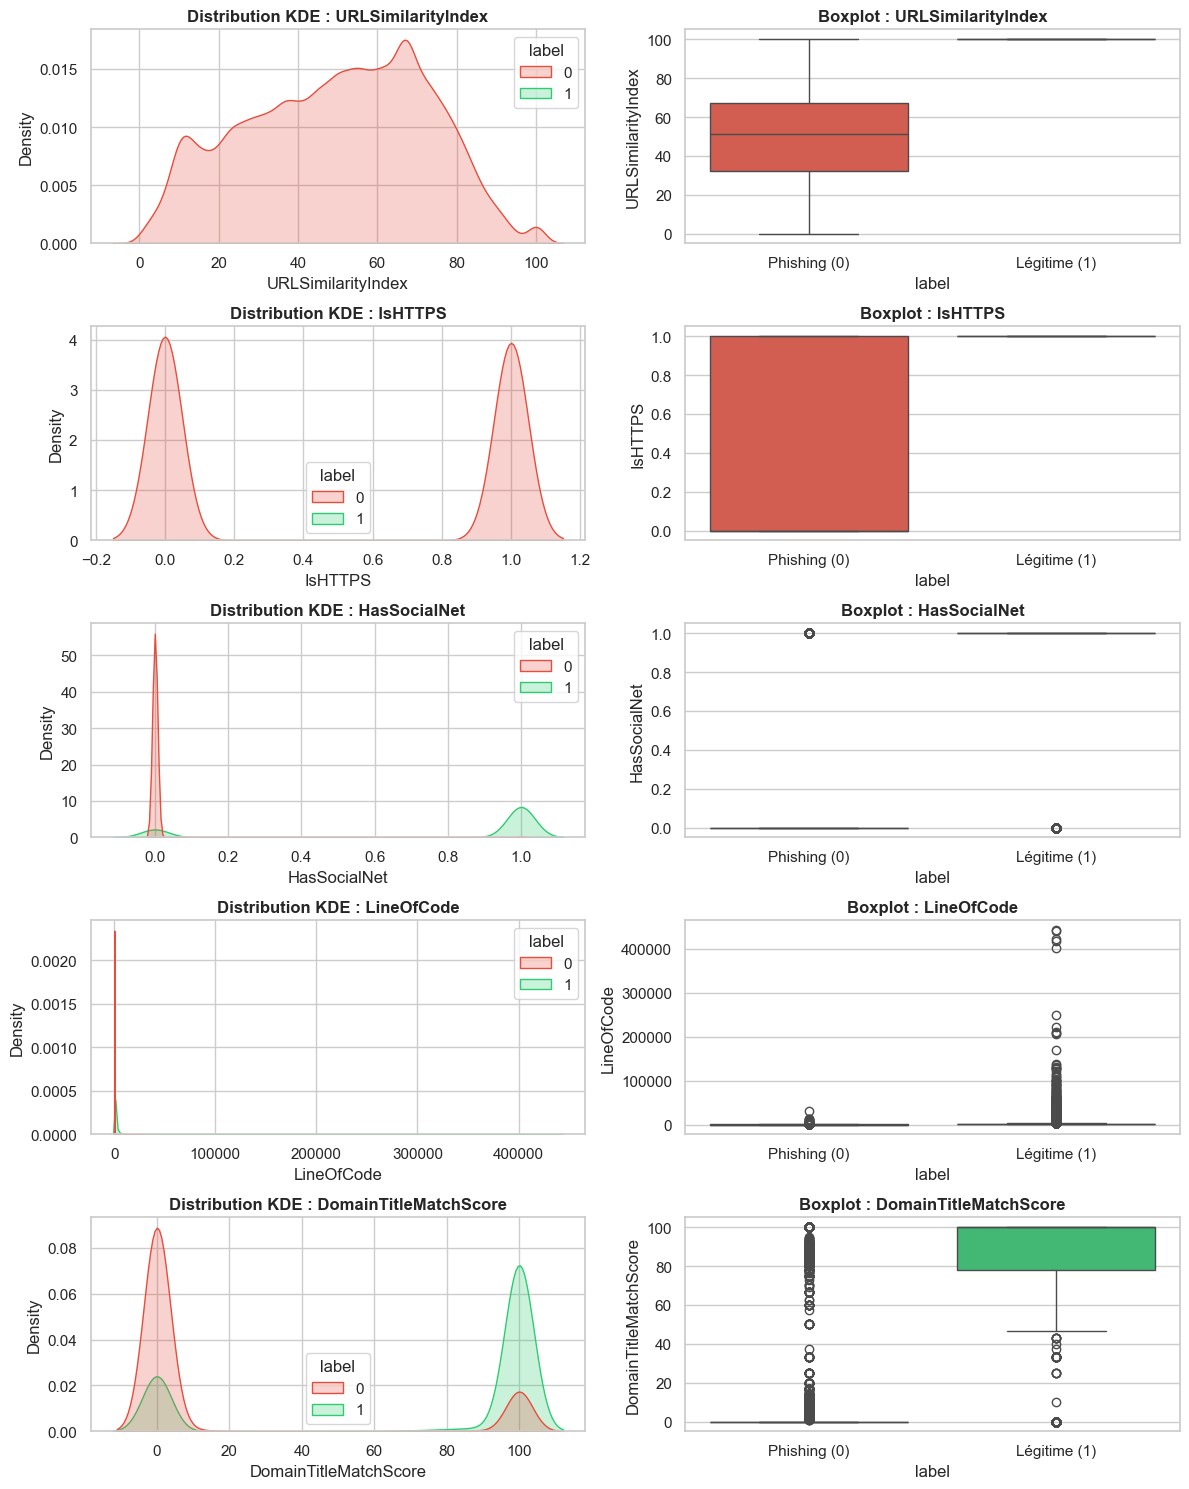

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo

# 1. Chargement et préparation des données
phiusiil = fetch_ucirepo(id=967)
df = pd.DataFrame(phiusiil.data.features).copy()
df['label'] = phiusiil.data.targets

# Configuration globale du style
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 10})

# ---------------------------------------------------------
# 1. DISTRIBUTION DE LA CIBLE
# ---------------------------------------------------------
plt.figure(figsize=(6, 4))
ax = sns.countplot(
    data=df,
    x='label',
    hue='label',
    palette=['#e74c3c', '#2ecc71'],
    legend=False
)
plt.title('Distribution de la Variable Cible (0 = Phishing, 1 = Légitime)', fontsize=12, fontweight='bold')
plt.xlabel('Label')
plt.ylabel('Effectif')
ax.set_xticks([0, 1])
ax.set_xticklabels(['Phishing (0)', 'Légitime (1)'])

total = len(df)
for p in ax.patches:
    percentage = f'{100 * p.get_height() / total:.1f}%\n({int(p.get_height()):,})'
    ax.annotate(percentage, (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                ha='center', va='center', fontsize=10, color='white', fontweight='bold')

plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 2. MATRICE DE CORRÉLATION DE SPEARMAN (Top 15 variables)
# ---------------------------------------------------------
numeric_df = df.select_dtypes(include=[np.number])
spearman_corr = numeric_df.corr(method='spearman')['label'].drop('label')

top_features = spearman_corr.abs().sort_values(ascending=False).head(15).index
top_corr_matrix = numeric_df[list(top_features) + ['label']].corr(method='spearman')

plt.figure(figsize=(10, 8))
sns.heatmap(top_corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
plt.title('Top 15 des Variables les plus Corrélées (Spearman)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 3. BOXPLOTS ET KDE PLOTS POUR LES VARIABLES CLEFS
# ---------------------------------------------------------
selected_features = ['URLSimilarityIndex', 'IsHTTPS', 'HasSocialNet', 'LineOfCode', 'DomainTitleMatchScore']
selected_features = [col for col in selected_features if col in df.columns]

fig, axes = plt.subplots(len(selected_features), 2, figsize=(12, 3 * len(selected_features)))

for i, col in enumerate(selected_features):
    # Plot KDE
    sns.kdeplot(
        data=df,
        x=col,
        hue='label',
        common_norm=False,
        palette=['#e74c3c', '#2ecc71'],
        ax=axes[i, 0],
        fill=True,
        warn_singular=False
    )
    axes[i, 0].set_title(f'Distribution KDE : {col}', fontweight='bold')

    # Plot Boxplot
    sns.boxplot(
        data=df,
        x='label',
        y=col,
        hue='label',
        palette=['#e74c3c', '#2ecc71'],
        ax=axes[i, 1],
        legend=False
    )
    axes[i, 1].set_title(f'Boxplot : {col}', fontweight='bold')
    axes[i, 1].set_xticks([0, 1])
    axes[i, 1].set_xticklabels(['Phishing (0)', 'Légitime (1)'])

plt.tight_layout()
plt.show()

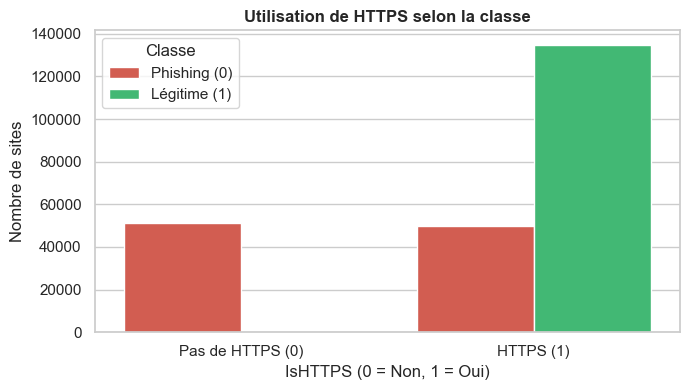

In [15]:
# Alternative très lisible pour les variables binaires comme IsHTTPS
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x='IsHTTPS', hue='label', palette=['#e74c3c', '#2ecc71'])
plt.title('Utilisation de HTTPS selon la classe', fontweight='bold')
plt.xlabel('IsHTTPS (0 = Non, 1 = Oui)')
plt.ylabel('Nombre de sites')
plt.xticks([0, 1], ['Pas de HTTPS (0)', 'HTTPS (1)'])
plt.legend(title='Classe', labels=['Phishing (0)', 'Légitime (1)'])
plt.tight_layout()
plt.show()

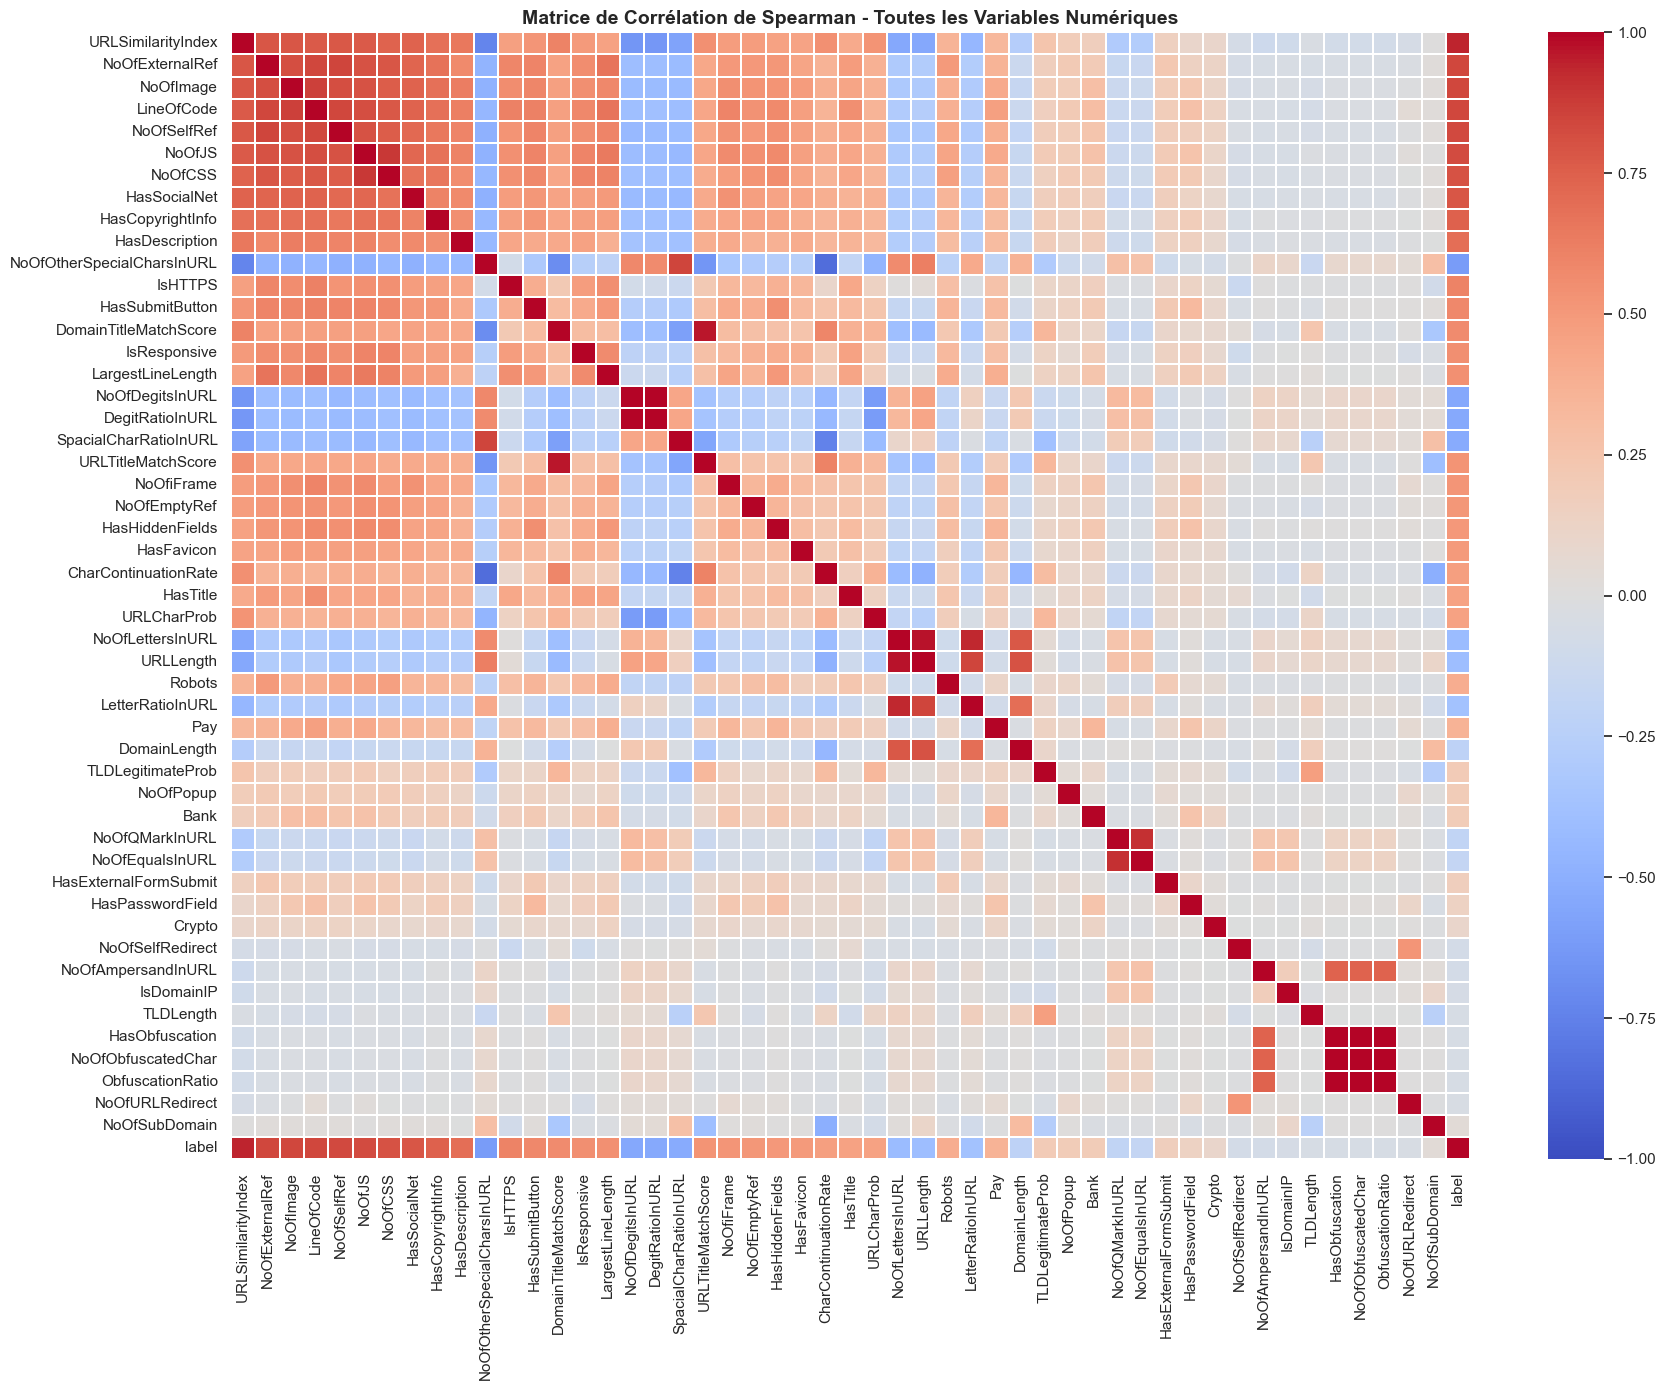

Nombre de variables binaires/discrètes : 21
Nombre de variables continues : 29


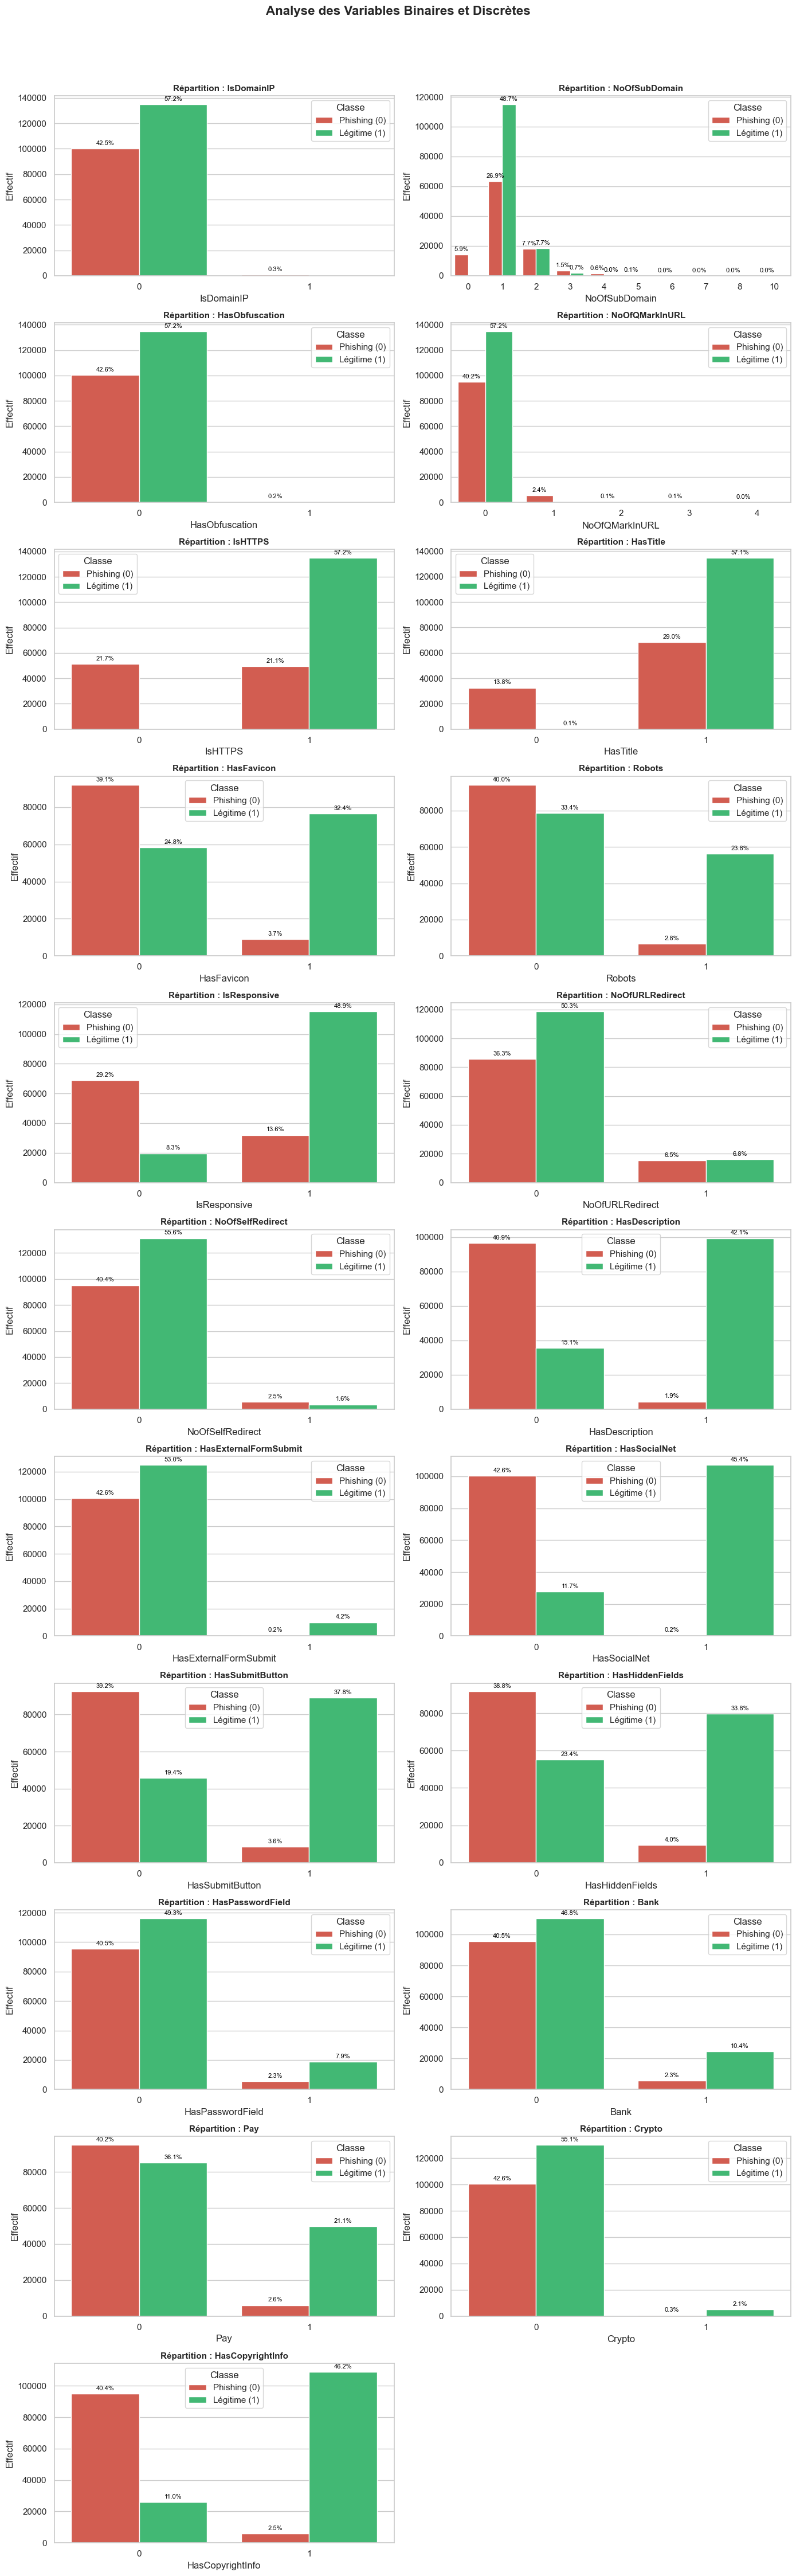

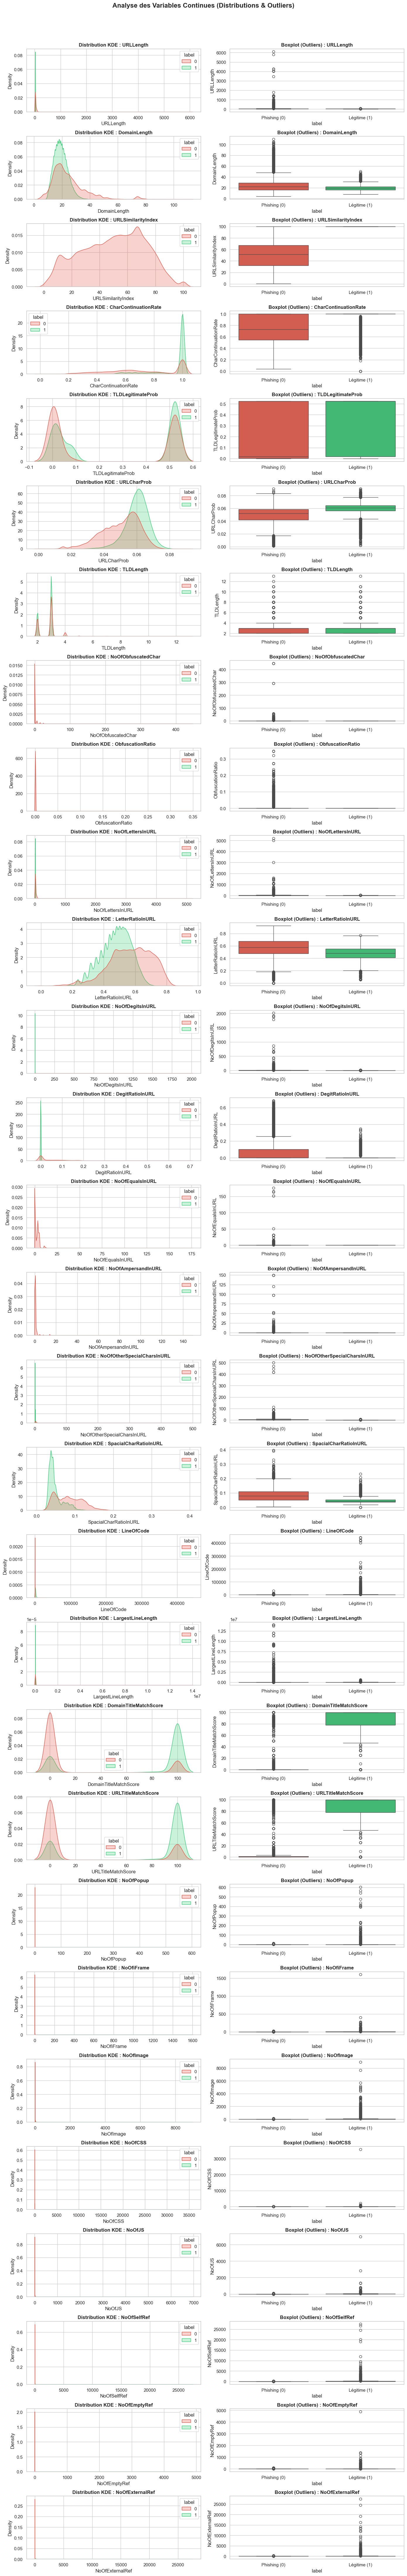

In [16]:
import math
# Style global
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 10})

# ---------------------------------------------------------
# 2. MATRICE DE CORRÉLATION DE SPEARMAN COMPLET (TOUTES LES FEATURES NUMÉRIQUES)
# ---------------------------------------------------------
numeric_df = df.select_dtypes(include=[np.number])

# Trier toutes les variables selon leur corrélation absolue avec la cible 'label'
correlations = numeric_df.corr(method='spearman')['label'].drop('label')
sorted_features = correlations.abs().sort_values(ascending=False).index.tolist()
sorted_corr_matrix = numeric_df[sorted_features + ['label']].corr(method='spearman')

# Taille dynamique selon le nombre de colonnes
plt.figure(figsize=(18, 14))
sns.heatmap(
    sorted_corr_matrix,
    annot=False,  # désactivé pour garder la carte lisible avec beaucoup de variables
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.1
)
plt.title('Matrice de Corrélation de Spearman - Toutes les Variables Numériques', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 3. SÉPARATION DES VARIABLES BINAIRES / DISCRÈTES ET CONTINUES
# ---------------------------------------------------------
# On exclut les variables non numériques et la cible 'label'
features_to_plot = [col for col in numeric_df.columns if col != 'label']

binary_or_discrete = []
continuous = []

for col in features_to_plot:
    if numeric_df[col].nunique() <= 10:  # Variables avec 10 valeurs uniques ou moins (ex: 0/1)
        binary_or_discrete.append(col)
    else:
        continuous.append(col)

print(f"Nombre de variables binaires/discrètes : {len(binary_or_discrete)}")
print(f"Nombre de variables continues : {len(continuous)}")

# ---------------------------------------------------------
# 4. ALTERNATIVE LISIBLE : BARPLOTS POUR TOUTES LES VARIABLES BINAIRES / DISCRÈTES
# ---------------------------------------------------------
if binary_or_discrete:
    n_cols = 2
    n_rows = math.ceil(len(binary_or_discrete) / n_cols)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 4 * n_rows))
    axes = axes.flatten()

    for i, col in enumerate(binary_or_discrete):
        ax = axes[i]
        sns.countplot(
            data=df,
            x=col,
            hue='label',
            palette=['#e74c3c', '#2ecc71'],
            ax=ax
        )
        ax.set_title(f'Répartition : {col}', fontweight='bold', fontsize=11)
        ax.set_xlabel(col)
        ax.set_ylabel('Effectif')
        ax.legend(title='Classe', labels=['Phishing (0)', 'Légitime (1)'])

        # Ajout des pourcentages au-dessus des barres
        total = len(df)
        for p in ax.patches:
            height = p.get_height()
            if height > 0:
                ax.annotate(f'{100 * height / total:.1f}%',
                            (p.get_x() + p.get_width() / 2., height),
                            ha='center', va='bottom', fontsize=8, color='black', xytext=(0, 3),
                            textcoords='offset points')

    # Masquer les axes superflus si le nombre de plots est impair
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.suptitle('Analyse des Variables Binaires et Discrètes', fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

# ---------------------------------------------------------
# 5. KDE + BOXPLOTS POUR TOUTES LES VARIABLES CONTINUES
# ---------------------------------------------------------
if continuous:
    fig, axes = plt.subplots(len(continuous), 2, figsize=(14, 3 * len(continuous)))

    # Gestion du cas où il n'y aurait qu'une seule variable continue
    if len(continuous) == 1:
        axes = np.expand_dims(axes, axis=0)

    for i, col in enumerate(continuous):
        # KDE
        sns.kdeplot(
            data=df,
            x=col,
            hue='label',
            common_norm=False,
            palette=['#e74c3c', '#2ecc71'],
            ax=axes[i, 0],
            fill=True,
            warn_singular=False
        )
        axes[i, 0].set_title(f'Distribution KDE : {col}', fontweight='bold')

        # Boxplot
        sns.boxplot(
            data=df,
            x='label',
            y=col,
            hue='label',
            palette=['#e74c3c', '#2ecc71'],
            ax=axes[i, 1],
            legend=False
        )
        axes[i, 1].set_title(f'Boxplot (Outliers) : {col}', fontweight='bold')
        axes[i, 1].set_xticks([0, 1])
        axes[i, 1].set_xticklabels(['Phishing (0)', 'Légitime (1)'])

    plt.suptitle('Analyse des Variables Continues (Distributions & Outliers)', fontsize=16, fontweight='bold', y=1.01)
    plt.tight_layout()
    plt.show()

In [17]:
tld_counts_train = x_train["TLD"].value_counts()

print("Nombre de TLD différents dans le train :", x_train["TLD"].nunique())

print("\n===== 30 TLD les plus fréquents =====")
print(tld_counts_train.head(30))

print("\n===== TLD rares =====")
print("TLD avec 1 seule occurrence :", (tld_counts_train == 1).sum())
print("TLD avec moins de 5 occurrences :", (tld_counts_train < 5).sum())
print("TLD avec moins de 10 occurrences :", (tld_counts_train < 10).sum())

Nombre de TLD différents dans le train : 667

===== 30 TLD les plus fréquents =====
TLD
com     89913
org     15027
net      5746
app      5191
uk       5143
co       4341
io       3317
de       3179
ru       3143
au       2426
top      1879
dev      1867
jp       1773
it       1538
edu      1479
fr       1475
br       1462
nl       1406
ca       1303
info     1262
xyz      1199
site     1193
link     1182
in       1086
pl       1051
gov      1006
cf        968
ga        872
us        869
me        812
Name: count, dtype: int64

===== TLD rares =====
TLD avec 1 seule occurrence : 162
TLD avec moins de 5 occurrences : 312
TLD avec moins de 10 occurrences : 401


In [18]:
tld_counts_train = x_train["TLD"].value_counts()

tld_frequents = tld_counts_train.head(30)

print("TLD conservés :", len(tld_frequents))
print("TLD regroupés dans Other :",  len(tld_counts_train) - len(tld_frequents))
couverture = tld_frequents.sum() / len(x_train) * 100
print(f"Les 30 TLD couvrent {couverture:.1f} % du train")

TLD conservés : 30
TLD regroupés dans Other : 637
Les 30 TLD couvrent 86.5 % du train



Sur les 667 TLD présents dans x_train :
- Top 30 most frequent TLD ayant 86% du dataset→ on les conserve.
- 637 TLD apparaissent moins couvrant presque 15% → on les regroupera dans Other.

In [19]:
liste_top30 = tld_frequents.index

x_train["TLD_grouped"] = x_train["TLD"].where(x_train["TLD"].isin(liste_top30), "Other")
x_test["TLD_grouped"] = x_test["TLD"].where(x_test["TLD"].isin(liste_top30), "Other")


In [20]:
print(x_train["TLD_grouped"].nunique())

print("\n===== Fréquences =====")
print(x_train["TLD_grouped"].value_counts().head(31))

print("\n===== Other =====")
print((x_train["TLD_grouped"] == "Other").sum())

31

===== Fréquences =====
TLD_grouped
com      89913
Other    25528
org      15027
net       5746
app       5191
uk        5143
co        4341
io        3317
de        3179
ru        3143
au        2426
top       1879
dev       1867
jp        1773
it        1538
edu       1479
fr        1475
br        1462
nl        1406
ca        1303
info      1262
xyz       1199
site      1193
link      1182
in        1086
pl        1051
gov       1006
cf         968
ga         872
us         869
me         812
Name: count, dtype: int64

===== Other =====
25528


In [21]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=True
)

tld_train_encoded = encoder.fit_transform(
    x_train[["TLD_grouped"]]
)

tld_test_encoded = encoder.transform(
    x_test[["TLD_grouped"]]
)
print("Dimensions train :", tld_train_encoded.shape)
print("Dimensions test :", tld_test_encoded.shape)

print("\nQuelques catégories encodées :")
print(encoder.get_feature_names_out())

Dimensions train : (188636, 31)
Dimensions test : (47159, 31)

Quelques catégories encodées :
['TLD_grouped_Other' 'TLD_grouped_app' 'TLD_grouped_au' 'TLD_grouped_br'
 'TLD_grouped_ca' 'TLD_grouped_cf' 'TLD_grouped_co' 'TLD_grouped_com'
 'TLD_grouped_de' 'TLD_grouped_dev' 'TLD_grouped_edu' 'TLD_grouped_fr'
 'TLD_grouped_ga' 'TLD_grouped_gov' 'TLD_grouped_in' 'TLD_grouped_info'
 'TLD_grouped_io' 'TLD_grouped_it' 'TLD_grouped_jp' 'TLD_grouped_link'
 'TLD_grouped_me' 'TLD_grouped_net' 'TLD_grouped_nl' 'TLD_grouped_org'
 'TLD_grouped_pl' 'TLD_grouped_ru' 'TLD_grouped_site' 'TLD_grouped_top'
 'TLD_grouped_uk' 'TLD_grouped_us' 'TLD_grouped_xyz']


In [22]:

# 1. Variables "Fuite de données" (HTML/DOM & Titres) à EXCLURE impérativement
html_and_leak_cols = [
    'URLSimilarityIndex', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'Title',
    'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots',
    'IsResponsive', 'HasDescription', 'NoOfPopup', 'NoOfiFrame',
    'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields',
    'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo',
    'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef',
    'NoOfExternalRef', 'IsHTTPS'
]

# 2. Comptages bruts à EXCLURE (car on privilégie exclusivement les RATIOS)
raw_count_cols = [
    'NoOfObfuscatedChar',
    'NoOfLettersInURL',
    'NoOfDegitsInURL',
    'NoOfEqualsInURL',
    'NoOfQMarkInURL',
    'NoOfAmpersandInURL',
    'NoOfOtherSpecialCharsInURL'
]

# 3. Métadonnées / Identifiants texte à exclure
metadata_cols = ['URL', 'Domain', 'TLD', 'TLD_grouped', 'label']

# Liste globale des colonnes à ignorer
cols_to_exclude = html_and_leak_cols + raw_count_cols + metadata_cols

# Extraction automatique des features retenues
num_features = [col for col in x_train.columns if col not in cols_to_exclude]

print(f" Nombre de variables retenues : {len(num_features)}")
print("\nListe finale des features d'URL & Ratios :")
for feat in num_features:
    print(f" - {feat}")

 Nombre de variables retenues : 15

Liste finale des features d'URL & Ratios :
 - URLLength
 - DomainLength
 - IsDomainIP
 - CharContinuationRate
 - TLDLegitimateProb
 - URLCharProb
 - TLDLength
 - NoOfSubDomain
 - HasObfuscation
 - ObfuscationRatio
 - LetterRatioInURL
 - DegitRatioInURL
 - SpacialCharRatioInURL
 - NoOfURLRedirect
 - NoOfSelfRedirect


In [23]:
import scipy.sparse as sp
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import cross_val_score

# Algorithmes
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

In [24]:

scaler = StandardScaler()

# Normalisation des features numériques
x_train_num_scaled = scaler.fit_transform(x_train[num_features].fillna(x_train[num_features].median()))
x_test_num_scaled = scaler.transform(x_test[num_features].fillna(x_train[num_features].median()))

# Fusion des variables numériques scalées avec le TLD One-Hot Encodé
X_train_final = sp.hstack((x_train_num_scaled, tld_train_encoded), format='csr')
X_test_final = sp.hstack((x_test_num_scaled, tld_test_encoded), format='csr')

# Assurer l'alignement de y (1 = Phishing, 0 = Légitime)
y_train_final = y_train.values if hasattr(y_train, 'values') else y_train
y_test_final = y_test.values if hasattr(y_test, 'values') else y_test

print("\nShape finale X_train :", X_train_final.shape)


Shape finale X_train : (188636, 46)


In [ ]:
# Dictionnaire des modèles prêts avec les meilleurs hyperparamètres par défaut
models = {
    "Logistic Regression": LogisticRegression(C=1.0, max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=15, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=20, random_state=42, n_jobs=-1),
    "XGBoost": XGBClassifier(n_estimators=100, learning_rate=0.1, random_state=42, eval_metric='logloss', n_jobs=-1)
}

results = []
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

start_time_global = time.time()

for idx, (name, clf) in enumerate(models.items()):
    print(f" Entraînement rapide de : {name}...")

    # Chronomètre individuel pour chaque modèle
    start_time_clf = time.time()

    # Fit direct sans GridSearchCV
    clf.fit(X_train_final, y_train_final)
    fit_time = time.time() - start_time_clf

    # Prédictions
    y_pred = clf.predict(X_test_final)

    if hasattr(clf, "predict_proba"):
        y_proba = clf.predict_proba(X_test_final)[:, 1]
    else:
        y_proba = y_pred

    # Métriques
    acc = accuracy_score(y_test_final, y_pred)
    prec = precision_score(y_test_final, y_pred)
    rec = recall_score(y_test_final, y_pred)
    f1 = f1_score(y_test_final, y_pred)
    roc_auc = roc_auc_score(y_test_final, y_proba)

    # Calcul des scores de Cross-Validation (5-fold CV)
    cv_scores = cross_val_score(clf, X_train_final, y_train_final, cv=5, scoring='f1', n_jobs=-1)

    results.append({
        "Modèle": name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-Score": f1,
        "ROC-AUC": roc_auc,
        "CV F1 Mean": cv_scores.mean(),     # Moyenne de la Validation Croisée
        "CV F1 Std": cv_scores.std(),       # Écart-type (stabilité du modèle)
        "Temps Fit (s)": round(fit_time, 3) # Temps d'entraînement
    })

    # Matrice de confusion
    cm = confusion_matrix(y_test_final, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx], cbar=False)
    axes[idx].set_title(f"{name}\nF1-Score: {f1:.4f}")
    axes[idx].set_xlabel("Prédit")
    axes[idx].set_ylabel("Réel")

plt.tight_layout()
plt.show()

print(f"\n Durée totale d'exécution : {round(time.time() - start_time_global, 2)} secondes.")

# Tableau comparatif
df_results = pd.DataFrame(results).sort_values(by="F1-Score", ascending=False)
display(df_results)

 Entraînement rapide de : Logistic Regression...
 Entraînement rapide de : Decision Tree...
 Entraînement rapide de : Random Forest...
 Entraînement rapide de : XGBoost...


In [ ]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.model_selection import cross_val_score

print("⚡ Évaluation accélérée de K-Nearest Neighbors (KNN)...")

# Fonction helper pour obtenir le nombre de lignes (compatible sparse matrix / DataFrame / Numpy)
get_n_samples = lambda X: X.shape[0] if hasattr(X, 'shape') else len(X)

n_train = get_n_samples(X_train_final)
n_test = get_n_samples(X_test_final)

# 1. Échantillonnage ultra-rapide (2000 lignes max)
np.random.seed(42)
idx_train_fast = np.random.choice(n_train, size=min(4000, n_train), replace=False)
idx_test_fast = np.random.choice(n_test, size=min(2000, n_test), replace=False)

# Découpage compatible matrices creuses et DataFrames
if hasattr(X_train_final, 'tocsr'): # Matrice creuse Scipy
    X_tr_knn = X_train_final.tocsr()[idx_train_fast]
    X_te_knn = X_test_final.tocsr()[idx_test_fast]
elif hasattr(X_train_final, 'iloc'): # DataFrame Pandas
    X_tr_knn = X_train_final.iloc[idx_train_fast]
    X_te_knn = X_test_final.iloc[idx_test_fast]
else: # Array Numpy
    X_tr_knn = X_train_final[idx_train_fast]
    X_te_knn = X_test_final[idx_test_fast]

if hasattr(y_train_final, 'iloc'):
    y_tr_knn = y_train_final.iloc[idx_train_fast]
    y_te_knn = y_test_final.iloc[idx_test_fast]
else:
    y_tr_knn = y_train_final[idx_train_fast]
    y_te_knn = y_test_final[idx_test_fast]

# 2. Instanciation de KNN
knn_model = KNeighborsClassifier(n_neighbors=5, weights='distance', n_jobs=-1)

# 3. Fit & Prédictions
start_time = time.time()
knn_model.fit(X_tr_knn, y_tr_knn)
fit_time = time.time() - start_time

y_pred_knn = knn_model.predict(X_te_knn)
y_proba_knn = knn_model.predict_proba(X_te_knn)[:, 1]

# 4. Cross-Validation (3-fold)
cv_scores_knn = cross_val_score(knn_model, X_tr_knn, y_tr_knn, cv=3, scoring='f1', n_jobs=-1)

# 5. Métriques
knn_metrics = {
    "Modèle": "KNN (Sampled)",
    "Accuracy": round(accuracy_score(y_te_knn, y_pred_knn), 4),
    "Precision": round(precision_score(y_te_knn, y_pred_knn), 4),
    "Recall": round(recall_score(y_te_knn, y_pred_knn), 4),
    "F1-Score": round(f1_score(y_te_knn, y_pred_knn), 4),
    "ROC-AUC": round(roc_auc_score(y_te_knn, y_proba_knn), 4),
    "CV F1 Mean": round(cv_scores_knn.mean(), 4),
    "CV F1 Std": round(cv_scores_knn.std(), 4),
    "Temps Fit (s)": round(fit_time, 3)
}

df_knn = pd.DataFrame([knn_metrics])
display(df_knn)

if 'results' in globals():
    results.append(knn_metrics)

print(f"✅ Terminé en {round(time.time() - start_time, 2)} secondes !")

⚡ Évaluation accélérée de K-Nearest Neighbors (KNN)...


,Modèle,Accuracy,Precision,Recall,F1-Score,ROC-AUC,CV F1 Mean,CV F1 Std,Temps Fit (s)
0,KNN (Sampled),0.91,0.8831,0.9701,0.9246,0.9496,0.9157,0.0046,0.004


✅ Terminé en 2.22 secondes !


In [ ]:
# Fusionner le résultat de KNN avec le tableau comparatif principal
df_results_complete = pd.concat([df_results, df_knn], ignore_index=True).sort_values(by="F1-Score", ascending=False)

print("=== TABLEAU COMPARATIF COMPLET (AVEC KNN) ===")
display(df_results_complete)

=== TABLEAU COMPARATIF COMPLET (AVEC KNN) ===


,Modèle,Accuracy,Precision,Recall,F1-Score,ROC-AUC,CV F1 Mean,CV F1 Std,Temps Fit (s)
0,XGBoost,0.994614,0.993425,0.997182,0.995300,0.998620,0.994923,0.000286,2.741
1,Decision Tree,0.986620,0.982452,0.994364,0.988372,0.993892,0.987944,0.000919,15.387
2,Random Forest,0.962213,0.941152,0.996218,0.967902,0.998082,0.968080,0.003588,101.331
4,KNN (Sampled),0.910000,0.883100,0.970100,0.924600,0.949600,0.915700,0.004600,0.004
3,Logistic Regression,0.893573,0.862527,0.968224,0.912324,0.944185,0.912090,0.000451,3.946


✅ Probabilités récupérées pour tous les modèles !


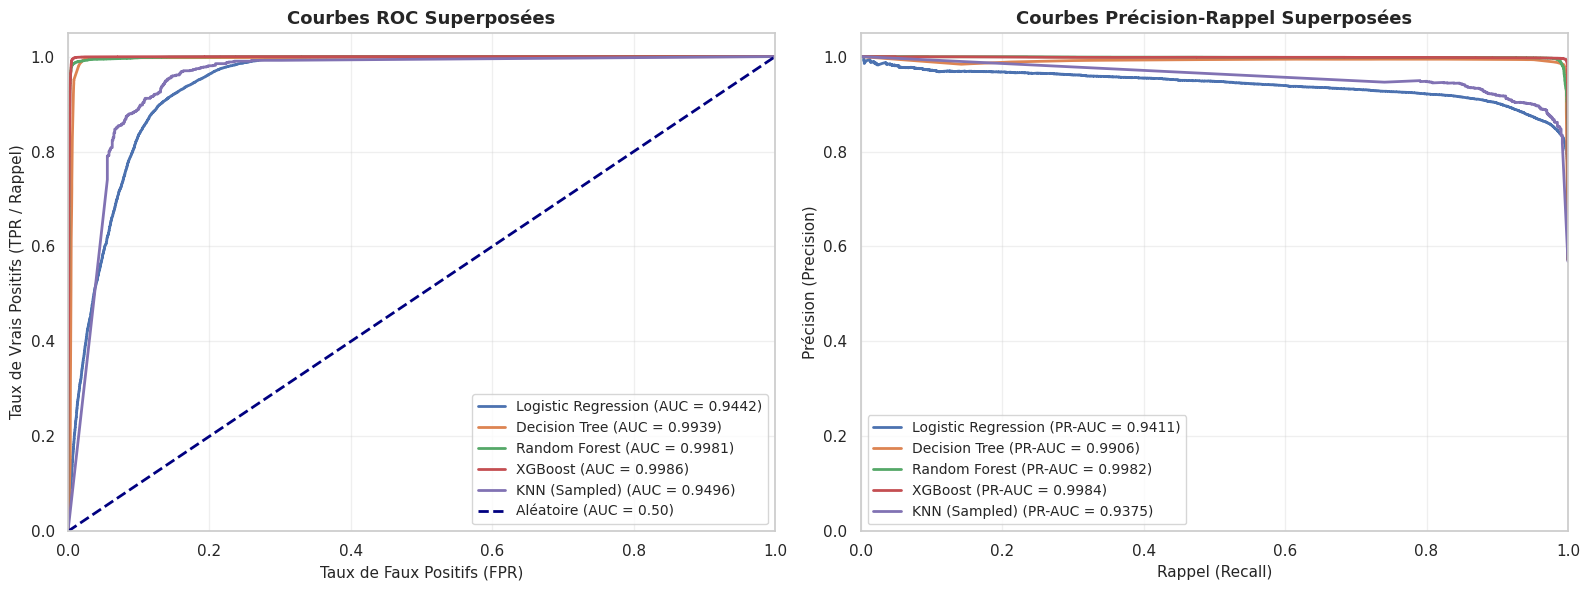

🎚️ Ajuste le curseur ci-dessous pour modifier le seuil de décision :


interactive(children=(FloatSlider(value=0.5, description='seuil', max=0.99, min=0.01, step=0.01), Output()), _…

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    roc_curve, auc,
    precision_recall_curve, average_precision_score,
    confusion_matrix, precision_score, recall_score, f1_score
)
from ipywidgets import interact, FloatSlider, Dropdown

# ---------------------------------------------------------
# 1. EXTRACTION DES PROBABILITÉS SANS RE-ENTRAÎNEMENT
# ---------------------------------------------------------
probas_dict = {}

# A. Extraction pour Logistic Regression, Decision Tree, Random Forest et XGBoost
for name, clf in models.items():
    if hasattr(clf, "predict_proba"):
        probas_dict[name] = clf.predict_proba(X_test_final)[:, 1]
    else:
        probas_dict[name] = clf.predict(X_test_final)

# B. Extraction pour KNN (sur son sous-ensemble X_te_knn et aligné avec y_te_knn)
if 'knn_model' in globals() and 'X_te_knn' in globals():
    probas_dict["KNN (Sampled)"] = knn_model.predict_proba(X_te_knn)[:, 1]

print("✅ Probabilités récupérées pour tous les modèles !")

# ---------------------------------------------------------
# 2. COURBES ROC ET PRÉCISION-RAPPEL SUPERPOSÉES (MODULE 4)
# ---------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# A. COURBES ROC SUPERPOSÉES
for name, probas in probas_dict.items():
    # Détermination du bon y_true (y_te_knn pour KNN, y_test_final pour les autres)
    y_true_curr = y_te_knn if name == "KNN (Sampled)" else y_test_final

    fpr, tpr, _ = roc_curve(y_true_curr, probas)
    roc_auc_val = auc(fpr, tpr)
    axes[0].plot(fpr, tpr, lw=2, label=f'{name} (AUC = {roc_auc_val:.4f})')

axes[0].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Aléatoire (AUC = 0.50)')
axes[0].set_xlim([0.0, 1.0])
axes[0].set_ylim([0.0, 1.05])
axes[0].set_xlabel('Taux de Faux Positifs (FPR)', fontsize=11)
axes[0].set_ylabel('Taux de Vrais Positifs (TPR / Rappel)', fontsize=11)
axes[0].set_title('Courbes ROC Superposées', fontsize=13, fontweight='bold')
axes[0].legend(loc="lower right", fontsize=10)
axes[0].grid(True, alpha=0.3)

# B. COURBES PRÉCISION-RAPPEL SUPERPOSÉES
for name, probas in probas_dict.items():
    y_true_curr = y_te_knn if name == "KNN (Sampled)" else y_test_final

    precision, recall, _ = precision_recall_curve(y_true_curr, probas)
    pr_auc_val = average_precision_score(y_true_curr, probas)
    axes[1].plot(recall, precision, lw=2, label=f'{name} (PR-AUC = {pr_auc_val:.4f})')

axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('Rappel (Recall)', fontsize=11)
axes[1].set_ylabel('Précision (Precision)', fontsize=11)
axes[1].set_title('Courbes Précision-Rappel Superposées', fontsize=13, fontweight='bold')
axes[1].legend(loc="lower left", fontsize=10)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 3. MATRICE DE CONFUSION & CURSEUR DE SEUIL DYNAMIQUE
# ---------------------------------------------------------
# Sélection du meilleur modèle (XGBoost ou Random Forest)
best_model_name = "XGBoost" if "XGBoost" in probas_dict else "Random Forest"
best_probas = probas_dict[best_model_name]
y_true_best = y_test_final

def plot_interactive_threshold(seuil):
    y_pred_custom = (best_probas >= seuil).astype(int)

    p = precision_score(y_true_best, y_pred_custom, zero_division=0)
    r = recall_score(y_true_best, y_pred_custom, zero_division=0)
    f1 = f1_score(y_true_best, y_pred_custom, zero_division=0)

    cm = confusion_matrix(y_true_best, y_pred_custom)

    fig, ax = plt.subplots(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Légitime (0)', 'Phishing (1)'],
                yticklabels=['Légitime (0)', 'Phishing (1)'])

    plt.title(f'Matrice de Confusion : {best_model_name}\n(Seuil de Décision = {seuil:.2f})', fontweight='bold', fontsize=11)
    plt.xlabel('Prédictions du Modèle', fontsize=10)
    plt.ylabel('Valeurs Réelles', fontsize=10)
    plt.show()

    print(f"📊 MÉTRIQUES EN DIRECT ({best_model_name} - Seuil = {seuil:.2f}) :")
    print(f" ├─ Précision : {p:.4f}")
    print(f" ├─ Rappel    : {r:.4f}")
    print(f" └─ F1-Score  : {f1:.4f}")

print("🎚️ Ajuste le curseur ci-dessous pour modifier le seuil de décision :")
interact(plot_interactive_threshold, seuil=FloatSlider(min=0.01, max=0.99, step=0.01, value=0.50));

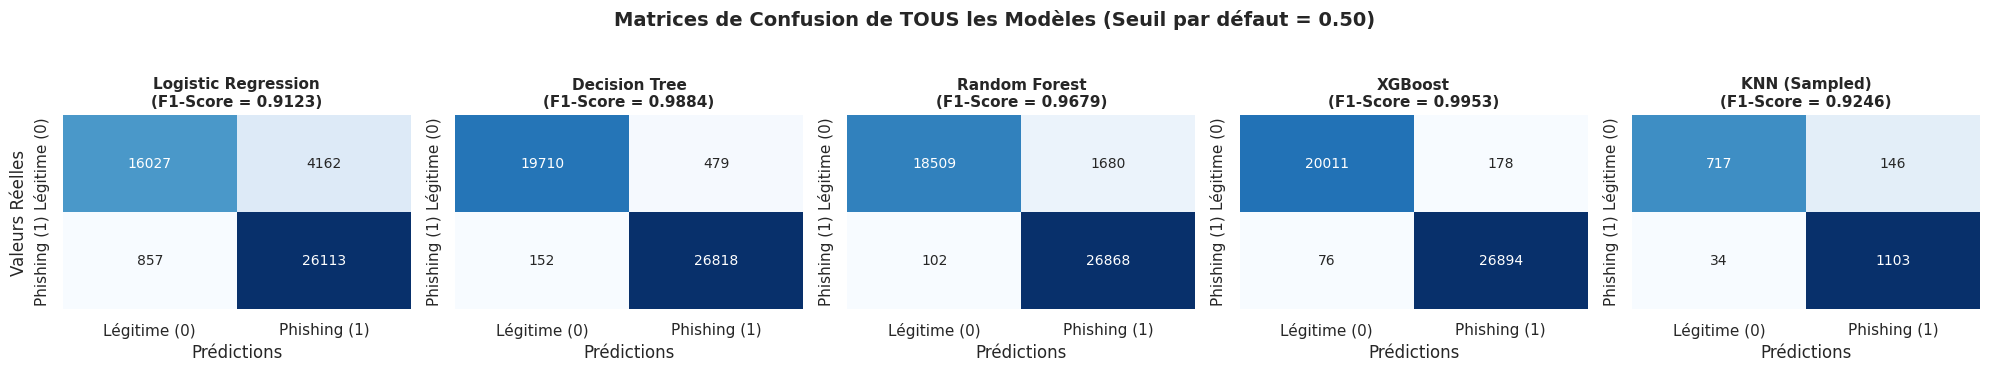


🎚️ Choisissez le modèle et déplacez le curseur pour tester l'impact du seuil :


interactive(children=(Dropdown(description='Modèle :', options=('Logistic Regression', 'Decision Tree', 'Rando…

In [ ]:
fig, axes = plt.subplots(1, len(probas_dict), figsize=(4 * len(probas_dict), 3.5))
if len(probas_dict) == 1:
    axes = [axes]

for idx, (name, probas) in enumerate(probas_dict.items()):
    y_true_curr = y_te_knn if name == "KNN (Sampled)" else y_test_final
    y_pred_default = (probas >= 0.50).astype(int)

    cm = confusion_matrix(y_true_curr, y_pred_default)

    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[idx],
                xticklabels=['Légitime (0)', 'Phishing (1)'],
                yticklabels=['Légitime (0)', 'Phishing (1)'])

    f1_val = f1_score(y_true_curr, y_pred_default, zero_division=0)
    axes[idx].set_title(f"{name}\n(F1-Score = {f1_val:.4f})", fontweight='bold', fontsize=11)
    axes[idx].set_xlabel('Prédictions')
    if idx == 0:
        axes[idx].set_ylabel('Valeurs Réelles')

plt.suptitle("Matrices de Confusion de TOUS les Modèles (Seuil par défaut = 0.50)", fontsize=14, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 2. CURSEUR DE SEUIL DYNAMIQUE INTERACTIF POUR TOUS LES MODÈLES
# ---------------------------------------------------------
def plot_all_models_threshold(modele_selectionne, seuil):
    probas = probas_dict[modele_selectionne]
    y_true_curr = y_te_knn if modele_selectionne == "KNN (Sampled)" else y_test_final

    # Prédictions selon le seuil
    y_pred_custom = (probas >= seuil).astype(int)

    p = precision_score(y_true_curr, y_pred_custom, zero_division=0)
    r = recall_score(y_true_curr, y_pred_custom, zero_division=0)
    f1 = f1_score(y_true_curr, y_pred_custom, zero_division=0)

    cm = confusion_matrix(y_true_curr, y_pred_custom)

    fig, ax = plt.subplots(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Légitime (0)', 'Phishing (1)'],
                yticklabels=['Légitime (0)', 'Phishing (1)'])

    plt.title(f'Matrice de Confusion : {modele_selectionne}\n(Seuil = {seuil:.2f})', fontweight='bold', fontsize=12)
    plt.xlabel('Prédictions du Modèle', fontsize=10)
    plt.ylabel('Valeurs Réelles', fontsize=10)
    plt.show()

    print(f"📊 MÉTRIQUES EN DIRECT ({modele_selectionne} - Seuil = {seuil:.2f}) :")
    print(f" ├─ Précision : {p:.4f}")
    print(f" ├─ Rappel    : {r:.4f}")
    print(f" └─ F1-Score  : {f1:.4f}")

print("\n🎚️ Choisissez le modèle et déplacez le curseur pour tester l'impact du seuil :")
interact(
    plot_all_models_threshold,
    modele_selectionne=Dropdown(options=list(probas_dict.keys()), value=list(probas_dict.keys())[0], description='Modèle :'),
    seuil=FloatSlider(min=0.01, max=0.99, step=0.01, value=0.50, description='Seuil :')
);

In [ ]:
import joblib
import os


os.makedirs("../models", exist_ok=True)

# Sauvegarde du modèle (ex: Random Forest ou XGBoost)
best_model_to_save = models["Random Forest"]  # ou models["XGBoost"]
joblib.dump(best_model_to_save, "../models/best_model.joblib")

print("✅ Modèle sauvegardé à la racine : phishing-xai/models/best_model.joblib")

NameError: name 'models' is not defined